# 05 – Machine-Learning Experiments

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 4 – Modelling and evaluation (classical ML)

### Goals
1. Load the feature panel (with optional regime labels)  
2. Train **more than three** classical ML models on a chronological split  
3. Compare against simple baselines (persistence, historical average)  
4. Evaluate return forecasting (regression) and direction (classification)  
5. Register the best models and persist metrics  

### Prerequisites
- Notebooks 01–03 completed (04 optional but recommended)  
- `data/processed/feature_panel.parquet` (or `feature_panel_with_regimes.parquet`)  
- `data/processed/feature_metadata.json`

In [1]:
# Cell 1 – Imports & setup

from __future__ import annotations

import sys
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings
from config.constants import ML_MODELS, RANDOM_SEED
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.analysis_results import save_analysis_result
from src.db.model_evaluations import save_model_evaluation

from src.models.baselines import (
    PersistenceBaseline,
    HistoricalAverageBaseline,
    SeasonalNaiveBaseline,
)
from src.models.evaluation import (
    chronological_split,
    evaluate_regression,
    evaluate_classification,
    run_baseline_comparison,
)
from src.models.ml import get_ml_model, MLTrainer, ML_MODEL_NAMES
from src.models.registry import ModelRegistry

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
np.random.seed(RANDOM_SEED)

print("Project root :", PROJECT_ROOT)
print("ML models    :", ML_MODEL_NAMES)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket
ML models    : ['ridge', 'random_forest', 'xgboost', 'lightgbm', 'catboost']


In [2]:
## 1. Load feature panel & metadata

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)

# Prefer the regime-enriched panel if it exists
panel_path = processed_dir / "feature_panel_with_regimes.parquet"
if not panel_path.exists():
    panel_path = processed_dir / "feature_panel.parquet"
if not panel_path.exists():
    raise FileNotFoundError("No feature panel found. Run notebook 03 first.")

panel = pd.read_parquet(panel_path)
panel = panel.loc[:, ~panel.columns.duplicated()].copy()

import json
with open(processed_dir / "feature_metadata.json", "r", encoding="utf-8") as f:
    feature_meta = json.load(f)

HORIZON = feature_meta.get("horizon", 5)
target_ret = f"target_ret_{HORIZON}d"
target_dir = f"target_dir_{HORIZON}d"

feature_cols = [
    c for c in feature_meta["feature_cols"]
    if c in panel.columns and pd.api.types.is_numeric_dtype(panel[c])
]
# Drop pure identifier / label columns from features if present
exclude = {"regime_cluster", "regime_id"}
feature_cols = [c for c in feature_cols if c not in exclude]

print(f"Panel shape     : {panel.shape}")
print(f"Features        : {len(feature_cols)}")
print(f"Target return   : {target_ret}")
print(f"Target direction: {target_dir}")
print(f"Splits          : {panel['split'].value_counts().to_dict()}")

Panel shape     : (45106, 46)
Features        : 37
Target return   : target_ret_5d
Target direction: target_dir_5d
Splits          : {'train': 31578, 'val': 6764, 'test': 6764}


## 2. Prepare train / validation / test matrices

We respect the chronological split already stored in the panel  
(`split` column = train / val / test).

In [3]:
# Cell 3 – Build X, y matrices

# Drop rows with missing target or features
work = panel.dropna(subset=[target_ret] + feature_cols).copy()

X_train = work.loc[work["split"] == "train", feature_cols]
y_train_ret = work.loc[work["split"] == "train", target_ret]
y_train_dir = work.loc[work["split"] == "train", target_dir]

X_val = work.loc[work["split"] == "val", feature_cols]
y_val_ret = work.loc[work["split"] == "val", target_ret]
y_val_dir = work.loc[work["split"] == "val", target_dir]

X_test = work.loc[work["split"] == "test", feature_cols]
y_test_ret = work.loc[work["split"] == "test", target_ret]
y_test_dir = work.loc[work["split"] == "test", target_dir]

print(f"Train : {X_train.shape[0]} rows")
print(f"Val   : {X_val.shape[0]} rows")
print(f"Test  : {X_test.shape[0]} rows")
print(f"Features: {X_train.shape[1]}")

Train : 29184 rows
Val   : 6764 rows
Test  : 6764 rows
Features: 37


In [4]:
## 3. Baseline comparison (required by the proposal)

baseline_results = run_baseline_comparison(
    y_train=y_train_ret.values,
    y_test=y_test_ret.values,
    X_test=X_test.values,
    horizon=HORIZON,
)

baseline_df = pd.DataFrame(baseline_results).T
print("Baseline performance on test set:")
display(baseline_df[["mae", "rmse", "r2", "directional_accuracy"]].round(5))

2026-10-12 12:30:17 | INFO     | src.models.evaluation | Baseline persistence           RMSE=0.085565  DirAcc=0.529
2026-10-12 12:30:17 | INFO     | src.models.evaluation | Baseline historical_average    RMSE=0.085112  DirAcc=0.529
2026-10-12 12:30:17 | INFO     | src.models.evaluation | Baseline seasonal_naive        RMSE=0.091834  DirAcc=0.494
Baseline performance on test set:


,mae,rmse,r2,directional_accuracy
persistence,0.06295,0.08556,-0.01680,0.52927
historical_average,0.06094,0.08511,-0.00607,0.52927
seasonal_naive,0.06786,0.09183,-0.17126,0.49394


## 4. Train classical ML models – Return forecasting (regression)

We evaluate: Ridge, Random Forest, XGBoost, LightGBM, CatBoost.

In [5]:
# Cell 5 – Regression experiments

# Models to run (subset if some libraries are missing)
REGRESSION_MODELS = ["ridge", "random_forest", "xgboost", "lightgbm", "catboost"]

regression_results = {}
registry = ModelRegistry(model_type="ml")

for name in REGRESSION_MODELS:
    print(f"\n>>> Training {name} (regression) ...")
    try:
        trainer = MLTrainer(
            model_name=name,
            task="regression",
            scale_features=True,
            random_state=RANDOM_SEED,
        )
        # Fit on train, evaluate on the chronological test set
        # We pass the full series and let the trainer do its own split
        # for internal consistency; here we already have explicit splits
        # so we fit manually for clarity.

        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_train)
        X_va = scaler.transform(X_val) if len(X_val) else np.empty((0, X_train.shape[1]))
        X_te = scaler.transform(X_test)

        model = get_ml_model(name, task="regression", random_state=RANDOM_SEED)
        model.fit(X_tr, y_train_ret.values)

        y_pred_te = model.predict(X_te)
        y_pred_va = model.predict(X_va) if len(X_va) else None

        metrics = evaluate_regression(y_test_ret.values, y_pred_te, prefix="test_")
        if y_pred_va is not None and len(y_val_ret):
            metrics.update(evaluate_regression(y_val_ret.values, y_pred_va, prefix="val_"))

        # Register
        model_id = registry.register(
            model,
            name=name,
            metrics=metrics,
            params={"task": "regression", "horizon": HORIZON},
            feature_cols=feature_cols,
            target=target_ret,
            horizon=HORIZON,
            train_end=feature_meta.get("train_end"),
            test_start=str(X_test.index.min().date()) if len(X_test) else None,
            test_end=str(X_test.index.max().date()) if len(X_test) else None,
        )
        metrics["model_id"] = model_id
        regression_results[name] = metrics
        print(f"  test_rmse={metrics.get('test_rmse', float('nan')):.5f}  "
              f"dir_acc={metrics.get('test_directional_accuracy', float('nan')):.3f}")
    except Exception as exc:
        logger.warning("Model %s failed: %s", name, exc)
        regression_results[name] = {"error": str(exc)}

reg_df = pd.DataFrame(
    {k: v for k, v in regression_results.items() if "error" not in v}
).T
print("\n=== Regression results (test set) ===")
display(reg_df[["test_mae", "test_rmse", "test_r2", "test_directional_accuracy"]].round(5))


>>> Training ridge (regression) ...
2026-10-12 12:31:00 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\ridge_20261012_070100_afd5042b.joblib
2026-10-12 12:31:01 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
2026-10-12 12:31:01 | INFO     | src.models.registry | Registered model_id=ridge_20261012_070100_afd5042b  (RMSE/metric keys=['test_mae', 'test_rmse', 'test_r2', 'test_mape', 'test_directional_accuracy', 'test_n_samples', 'val_mae', 'val_rmse', 'val_r2', 'val_mape', 'val_directional_accuracy', 'val_n_samples'])
  test_rmse=0.08695  dir_acc=0.518

>>> Training random_forest (regression) ...
2026-10-12 12:31:39 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\random_forest_20261012_070138_9587c605.joblib
2026-10-12 12:31:39 | INFO     | src.models.registry | Registered mo

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  test_rmse=0.09021  dir_acc=0.498

>>> Training catboost (regression) ...
2026-10-12 12:31:56 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\catboost_20261012_070156_6df1f318.joblib
2026-10-12 12:31:56 | INFO     | src.models.registry | Registered model_id=catboost_20261012_070156_6df1f318  (RMSE/metric keys=['test_mae', 'test_rmse', 'test_r2', 'test_mape', 'test_directional_accuracy', 'test_n_samples', 'val_mae', 'val_rmse', 'val_r2', 'val_mape', 'val_directional_accuracy', 'val_n_samples'])
  test_rmse=0.08692  dir_acc=0.515

=== Regression results (test set) ===


,test_mae,test_rmse,test_r2,test_directional_accuracy
ridge,0.061937,0.086948,-0.049948,0.518037
random_forest,0.062548,0.087113,-0.053924,0.519959
xgboost,0.065489,0.090776,-0.144441,0.494086
lightgbm,0.064937,0.090215,-0.130326,0.497635
catboost,0.062221,0.086917,-0.049192,0.514784


In [6]:
## 5. Direction classification experiments

CLASSIFICATION_MODELS = ["ridge", "random_forest", "xgboost", "lightgbm", "catboost"]

classification_results = {}

for name in CLASSIFICATION_MODELS:
    print(f"\n>>> Training {name} (classification) ...")
    try:
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_train)
        X_te = scaler.transform(X_test)

        model = get_ml_model(name, task="classification", random_state=RANDOM_SEED)
        model.fit(X_tr, y_train_dir.values.astype(int))

        y_pred = model.predict(X_te)
        metrics = evaluate_classification(
            y_test_dir.values.astype(int),
            y_pred,
            prefix="test_",
        )

        model_id = registry.register(
            model,
            name=f"{name}_clf",
            metrics={k: v for k, v in metrics.items() if k != "test_confusion_matrix"},
            params={"task": "classification", "horizon": HORIZON},
            feature_cols=feature_cols,
            target=target_dir,
            horizon=HORIZON,
        )
        metrics["model_id"] = model_id
        classification_results[name] = metrics
        print(f"  test_accuracy={metrics.get('test_accuracy', float('nan')):.3f}  "
              f"f1={metrics.get('test_f1', float('nan')):.3f}")
    except Exception as exc:
        logger.warning("Classifier %s failed: %s", name, exc)
        classification_results[name] = {"error": str(exc)}

clf_df = pd.DataFrame(
    {k: v for k, v in classification_results.items() if "error" not in v}
).T
print("\n=== Classification results (test set) ===")
cols = [c for c in ["test_accuracy", "test_balanced_accuracy", "test_precision",
                    "test_recall", "test_f1"] if c in clf_df.columns]
display(clf_df[cols].round(4))


>>> Training ridge (classification) ...
2026-10-12 12:34:17 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\ridge_clf_20261012_070416_e941b7fd.joblib
2026-10-12 12:34:17 | INFO     | src.models.registry | Registered model_id=ridge_clf_20261012_070416_e941b7fd  (RMSE/metric keys=['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_n_samples'])
  test_accuracy=0.499  f1=0.499

>>> Training random_forest (classification) ...
2026-10-12 12:34:24 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\random_forest_clf_20261012_070423_91bf919d.joblib
2026-10-12 12:34:24 | INFO     | src.models.registry | Registered model_id=random_forest_clf_20261012_070423_91bf919d  (RMSE/metric keys=['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_n_samples'])
  test_accuracy=0.511  f1=0.

c:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  test_accuracy=0.505  f1=0.504

>>> Training catboost (classification) ...
2026-10-12 12:34:35 | INFO     | src.models.registry | Saved model artifact → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\models\ml\catboost_clf_20261012_070435_78944eb7.joblib
2026-10-12 12:34:35 | INFO     | src.models.registry | Registered model_id=catboost_clf_20261012_070435_78944eb7  (RMSE/metric keys=['test_accuracy', 'test_balanced_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_n_samples'])
  test_accuracy=0.514  f1=0.513

=== Classification results (test set) ===


,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1
ridge,0.499113,0.502532,0.502558,0.502532,0.498692
random_forest,0.511384,0.508496,0.508552,0.508496,0.508308
xgboost,0.507096,0.514468,0.515381,0.514468,0.502531
lightgbm,0.505322,0.510187,0.510436,0.510187,0.503917
catboost,0.514045,0.518445,0.518794,0.518445,0.513068


Test RMSE ranking (lower is better):


,test_rmse,dir_acc
model,,
baseline_historical_average,0.08511,0.52927
baseline_persistence,0.08556,0.52927
catboost,0.08692,0.51478
ridge,0.08695,0.51804
random_forest,0.08711,0.51996
lightgbm,0.09021,0.49763
xgboost,0.09078,0.49409
baseline_seasonal_naive,0.09183,0.49394


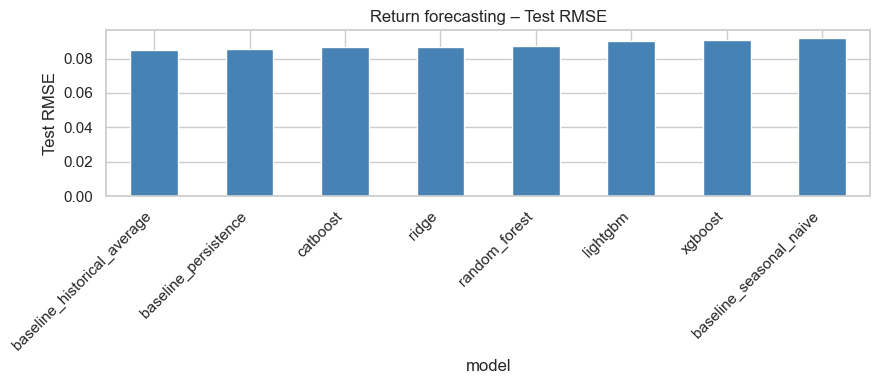

In [7]:
## 6. Summary comparison vs baselines

# Regression RMSE comparison
rmse_rows = []
for name, m in baseline_results.items():
    rmse_rows.append({"model": f"baseline_{name}", "test_rmse": m["rmse"],
                      "dir_acc": m["directional_accuracy"]})
for name, m in regression_results.items():
    if "error" in m:
        continue
    rmse_rows.append({
        "model": name,
        "test_rmse": m.get("test_rmse"),
        "dir_acc": m.get("test_directional_accuracy"),
    })

cmp_df = pd.DataFrame(rmse_rows).set_index("model").sort_values("test_rmse")
print("Test RMSE ranking (lower is better):")
display(cmp_df.round(5))

fig, ax = plt.subplots(figsize=(9, 4))
cmp_df["test_rmse"].plot.bar(ax=ax, color="steelblue")
ax.set_ylabel("Test RMSE")
ax.set_title("Return forecasting – Test RMSE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
## 7. Persist experiment results

results_doc = {
    "run_at": utc_now().isoformat(),
    "horizon": HORIZON,
    "n_features": len(feature_cols),
    "n_train": int(len(X_train)),
    "n_val": int(len(X_val)),
    "n_test": int(len(X_test)),
    "baselines": baseline_results,
    "regression": {
        k: {kk: vv for kk, vv in v.items() if kk != "test_confusion_matrix"}
        for k, v in regression_results.items()
    },
    "classification": {
        k: {kk: vv for kk, vv in v.items() if kk != "test_confusion_matrix"}
        for k, v in classification_results.items()
    },
}

results_path = processed_dir / "ml_experiment_results.json"
save_json(results_doc, results_path)
print(f"Saved ML results → {results_path}")

# MongoDB summary
save_analysis_result({
    "analysis_type": "ml_experiments",
    "as_of": utc_now().isoformat(),
    "payload": {
        "horizon": HORIZON,
        "n_models_regression": len([v for v in regression_results.values() if "error" not in v]),
        "n_models_classification": len([v for v in classification_results.values() if "error" not in v]),
        "best_regression_rmse": float(cmp_df["test_rmse"].min()) if len(cmp_df) else None,
        "best_regression_model": str(cmp_df["test_rmse"].idxmin()) if len(cmp_df) else None,
    },
})
print("ML experiment summary written to MongoDB")

Saved ML results → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\ml_experiment_results.json
ML experiment summary written to MongoDB


## 8. Acceptance criteria (Notebook 05)

| Criterion | Status |
|-----------|--------|
| ≥ 3 ML algorithms evaluated | Cell 5 (Ridge, RF, XGB, LGBM, CatBoost) |
| Chronological train/val/test | Cell 3 |
| Baseline comparison | Cell 4 |
| Regression + classification tasks | Cells 5-6 |
| Models registered in ModelRegistry | Cells 5-6 |
| Results persisted | Cell 8 |

**Next notebook:** `06_dl_experiments.ipynb` – deep-learning sequence models.

In [9]:
print("Notebook 05 finished successfully.")
if len(cmp_df):
    print(f"Best regression model by RMSE: {cmp_df['test_rmse'].idxmin()} "
          f"({cmp_df['test_rmse'].min():.5f})")

Notebook 05 finished successfully.
Best regression model by RMSE: baseline_historical_average (0.08511)
